# Linear Regression

## Introduction

> [Linear Regression and Ordinary Least Squares | DotCSV](https://www.youtube.com/watch?v=k964_uNn3l0) (video, in Spanish)


**Linear regression** is a statistical method that allows us to model the relationship between a **dependent variable** $Y$ and one or more **independent variables** $X_i$ (also called **predictors** or **features**). The objective is to find a **linear function** $f$ that allows us to predict the value of $Y$ for any value of $X_i$.

To simplify and understand the basic concepts, in this example we will create a model that predicts an employee's salary considering only their years of experience. That is, we will use a single independent variable, which means we are dealing with a case of **simple linear regression**. It is evident that it would be necessary to analyze more variables to have a better model. If we wanted to consider more independent variables (e.g., education level, type of work, industry sector, city, etc.), we would need to use a **multiple linear regression** model.

## The Data

The data are the salaries of the employees of a company, with each employee's years of experience. They are simulated, which has an advantage: we know the relationship a model should find. Each salary is a starting salary of €22,000 a year, plus €2,600 for each year of experience, plus a difference between employees that experience doesn't explain (random, with a standard deviation of €4,000). `numpy` draws the random numbers, and `pandas` holds them in a table, a *DataFrame*:

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=42)  # a fixed seed draws the same numbers every time the notebook runs
years = rng.uniform(0, 12, size=30).round(1)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=30)
df = pd.DataFrame({"YearsExperience": years, "Salary": salary.round(-2)})

In [ ]:
df.head() # Display the first 5 rows for a preview of the data

,YearsExperience,Salary
0,9.3,54700.0
1,5.3,34200.0
2,10.3,46700.0
3,8.4,40600.0
4,1.1,27300.0


In [ ]:
df.info() # Display information about the dataframe

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


If our goal is to estimate the salary that an employee will have based on their years of experience, we will consider the number of years of experience as the **independent variable** (also called predictor or feature) and the salary as the **dependent variable** (also called target or response variable). 

This means we are modeling a **relationship between both variables**: we assume that salary depends on (is a function of) the employee's years of experience. Choosing the target is choosing what to predict, not a claim about causes: a model that predicts salaries from experience doesn't show that experience *causes* a higher salary, and correlation alone never proves causation.

## Data Visualization

We will create a **scatter plot** to visualize the relationship between both variables.

A scatter plot displays Cartesian coordinates to show the values of two variables for a dataset. In this case, we will visualize one point for each employee, where the X-axis represents years of experience and the Y-axis represents their salary.

We use the `dataframe.plot` method from **pandas** to create the scatter plot. This method, in turn, uses the **matplotlib** library to generate the visualization.

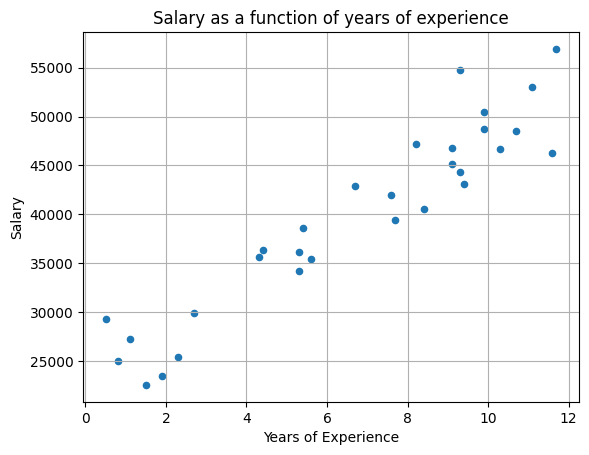

In [ ]:
df.plot(kind='scatter', # Create a scatter plot
        x='YearsExperience', # X-axis (independent variable)
        y='Salary', # Y-axis (dependent variable)
        title='Salary as a function of years of experience',
        grid=True, # Show grid
        xlabel='Years of Experience', # X-axis label
        ylabel='Salary');  # Y-axis label

We can observe a clear **correlation** between both variables: the greater the number of years of experience, the higher the salary. And the relationship appears quite linear, meaning we can approximate it with a straight line (for one predictor; in multiple linear regression it would be a plane or a **hyperplane**).

The data provides us with a sample of reality, and we seek to find a **model** that describes it. When we later apply the model to an employee for whom we only know their years of experience, we will obtain a **prediction** of their salary.

## Linear Regression Model

We are therefore looking for a straight line that is the model that best fits the data. Knowing that a straight line is defined by the formula
$$\mathbf{y = m*x + b}$$
(where $m$ is the slope of the line and $b$ is the y-intercept), we need to find the values of $m$ and $b$ that best fit the data.

**The model will be formed by this formula, and the model parameters are the coefficients $\mathbf{m}$ and $\mathbf{b}$**.

In [ ]:
# Define x as a vector with years of experience data and y as a vector with salary data corresponding to each value of x
x = df['YearsExperience'].values # .values converts that dataframe column into a numpy array
y = df['Salary'].values

We import the `linear_model.LinearRegression` class from the **scikit-learn** library. This class implements the linear regression **model** and allows us to **train** it with the data we have.

Documentation on linear models in scikit-learn: https://scikit-learn.org/stable/modules/linear_model.html

In [ ]:
from sklearn.linear_model import LinearRegression

The `LinearRegression.fit()` method receives the values of the independent and dependent variables as parameters and calculates the values of the **model parameters** that best fit the data.

In [ ]:
model = LinearRegression().fit(x.reshape(-1, 1), y) # Fit the linear regression model

In this case, we only have one independent variable x (years of experience), but we could have more (**LinearRegression also supports multiple linear regression**). That is why `fit` expects its first argument to be two-dimensional, a matrix with one row per sample and one column per independent variable, even when there is only one column. `reshape(-1, 1)` turns our one-dimensional array of 30 values into a matrix of 30 rows and 1 column (the `-1` stands for "as many rows as needed").

We could also pass the columns of the DataFrame directly. The result is the same model, which also remembers the names of its features:

In [ ]:
model_from_dataframe = LinearRegression().fit(df[['YearsExperience']], df['Salary'])
model_from_dataframe.feature_names_in_

array(['YearsExperience'], dtype=object)

It is important to remember that `df[['YearsExperience']]` returns a dataframe with a single column, while `df['Salary']` returns a series. For the dependent variable (y), the method accepts both options, although it is more common to pass a series since it predicts a single dependent variable. However, for independent variables (x), it only accepts data in columns since there can be more than one independent variable, in which case we should pass a dataframe with as many columns as there are independent variables. This is the same reason why, when using NumPy, we use `reshape`.

In [ ]:
m = model.coef_[0] # Slope (coefficient of x)
b = model.intercept_ # Y-intercept

# With these two values, by applying the line formula, we can calculate the predicted value for any value of x
ŷ = m * x + b

In this case, we use the notation ŷ to refer to predictions of the dependent variable $y$. That is:
- ŷ is the value that the model predicts for a value of $x$
- y are the actual values of the dependent variable (the samples we have from the beginning)

This notation is more mathematical/statistical than Python-specific, but it is widely used in the data science field.

### Visualization of the Regression Line and Its Residuals

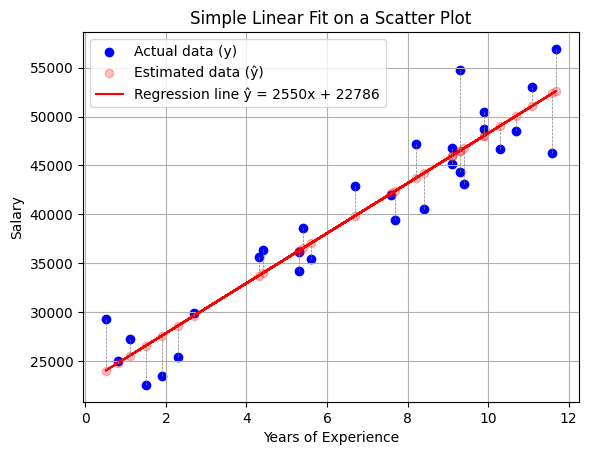

In [ ]:
# matplotlib directly, for a plot with more elements than the previous one
from matplotlib import pyplot as plt

# Plot the actual data (y) and the estimated data (ŷ) as scatter points
plt.scatter(x, y, c='blue', label='Actual data (y)')
plt.scatter(x, ŷ, c='red', label='Estimated data (ŷ)', alpha=0.25) # alpha is the transparency of the points in the scatter function
# Plot the regression line
plt.plot(x, ŷ,  c='red', label=f'Regression line ŷ = {round(m)}x + {round(b)}')

# Draw error lines (lines from the input data to the fitted line)
for xi, yi, ŷi in zip(x, y, ŷ): # zip() associates elements from the lists into tuples, we unpack and iterate over each trio of elements
    plt.plot([xi, xi], [yi, ŷi], c='gray', linestyle='--', linewidth=.5) # draws a line from point (xi, yi) to point (xi, ŷi)

plt.xlabel('Years of Experience')  # X-axis label
plt.ylabel('Salary')  # Y-axis label
plt.title('Simple Linear Fit on a Scatter Plot')
plt.legend() # Show legend
plt.grid(True) # Add grid
plt.show() # Display the plot

In [ ]:
x, y, ŷ

(array([ 9.3,  5.3, 10.3,  8.4,  1.1, 11.7,  9.1,  9.4,  1.5,  5.4,  4.4,
        11.1,  7.7,  9.9,  5.3,  2.7,  6.7,  0.8,  9.9,  7.6,  9.1,  4.3,
        11.6, 10.7,  9.3,  2.3,  5.6,  0.5,  1.9,  8.2]),
 array([54700., 34200., 46700., 40600., 27300., 56900., 45200., 43100.,
        22600., 38600., 36400., 53000., 39400., 48700., 36200., 29900.,
        42900., 25000., 50500., 42000., 46800., 35700., 46300., 48500.,
        44300., 25400., 35500., 29300., 23500., 47200.]),
 array([46501.83684633, 36301.31795596, 49051.96656892, 44206.720096  ,
        25590.77312108, 52622.14818055, 45991.81090181, 46756.84981859,
        26610.82501011, 36556.33092822, 34006.20120563, 51092.070347  ,
        42421.62929018, 48031.91467989, 36301.31795596, 29670.98067722,
        39871.49956759, 24825.7342043 , 48031.91467989, 42166.61631792,
        45991.81090181, 33751.18823337, 52367.13520829, 50072.01845796,
        46501.83684633, 28650.92878819, 37066.35687274, 24060.69528752,
        27630.87

We can see each of the points along with the regression line we calculated and the **residual** for each data point with respect to the model's prediction. What we have sought is the line that makes these **residuals** as small as possible.

The legend shows the line the model found. It is close to the relationship we simulated, €2,600 per year from a start of €22,000, but not equal to it: the model only sees 30 employees, and their random differences pull the line a little one way or the other.

**Important distinction:**
- **Residual:** the difference between an observed value and the value our model predicts ($y - \hat y$). This is what we calculate and visualize.
- **Error:** the difference between an observed value and the true relationship, the part of the salary that experience doesn't explain. With real data the true relationship is unknown, and so are the errors; here we know them, because they are the random differences we added when simulating the salaries.

We can observe residuals, but not errors. Training minimizes the residuals as a whole: the sum of their squares, which is the same as minimizing their mean, the **mean squared error (MSE)**.

In the previous explanation, we extract the model coefficients and calculate the line formula with them to help understand the concept, but we could actually do it directly with the `LinearRegression.predict()` method, which returns the predictions for the input values we pass to it:

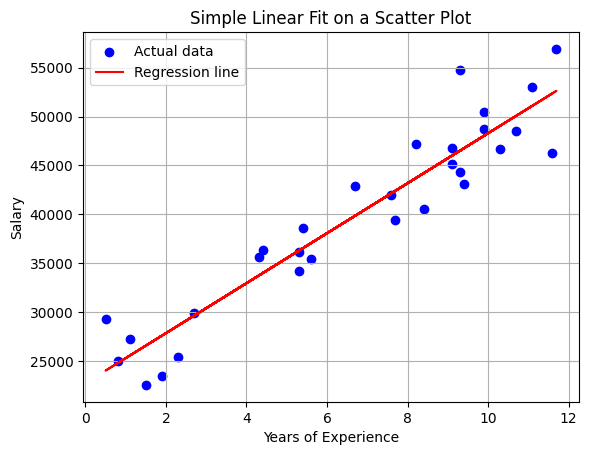

In [ ]:
plt.scatter(x, y, c='blue', label='Actual data')
plt.plot(x, model.predict(x.reshape(-1, 1)), c='red', label=f'Regression line')

plt.xlabel('Years of Experience')  # X-axis label
plt.ylabel('Salary')  # Y-axis label
plt.title('Simple Linear Fit on a Scatter Plot')
plt.legend() # Show legend
plt.grid(True) # Add grid
plt.show() # Display the plot

## Error Metrics / Cost Functions

There are different metrics to measure the error of a regression model. The most common are mean squared error (MSE) and mean absolute error (MAE).

These metrics are also used as **cost functions** to minimize when training the model. Without a function to minimize, "the line that best fits the data" would have no precise meaning: training *is* the search for its minimum. Three related words appear in this context:

- The **loss** is the error on a single example, such as the squared residual $(y_i - \hat y_i)^2$.
- The **cost function** is what training minimizes over the whole training set, usually the mean of the losses: the MSE is the mean of the squared residuals. Many texts, and libraries such as scikit-learn, call it the loss too.
- A **metric** is what we report to judge a model, and it need not be the function the model was trained on: a line fitted by minimizing the MSE can be judged by its MAE, and the classifiers of part 4 are trained on one function and judged by others.

### Mean Absolute Error (MAE)

One way to calculate error is using the **mean absolute error (MAE)**, which is the mean of the absolute errors made when taking $\hat y$ as the prediction of $y$.

$$MAE(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|$$

This metric is the most intuitive, as it gives us an idea of how much the model is wrong in each prediction. However, it has a problem: it requires using the absolute value of the errors to prevent them from canceling each other out (negative errors subtracting from positive ones), since we don't care whether the prediction is above or below the actual value—what matters to us is how far away it is. The absolute value has a corner at 0, where it has no derivative, and the MAE has no formula that gives its minimum directly: **optimization algorithms** can still minimize it, but with more work than the squared error, one reason why least squares became the standard way to fit a line. The problem of calculating the line that best fits the data is an **optimization problem**, since what we are looking for is to **minimize the cost function**.

In [ ]:
mae = np.mean(np.abs(y - ŷ))
print("MAE calculated by its formula: ", mae)

from sklearn.metrics import mean_absolute_error
print("MAE calculated with scikit-learn: ", mean_absolute_error(y, ŷ))

MAE calculated by its formula:  2573.2137992083617
MAE calculated with scikit-learn:  2573.2137992083617


### Mean Squared Error (MSE)

Due to the problems with MAE, it is common to use the **mean squared error (MSE)**, which is the mean of the squared errors.

$$ MSE(y, \hat y)= \frac{1}{n}\sum_{i=1}^{n}{(y_i-\hat y_i)^2}$$

By squaring the errors, we are already preventing them from canceling each other out. Additionally, being a quadratic function, it is differentiable at all points, which facilitates its use in optimization algorithms.

It should be noted that by squaring, we penalize **outliers** (those that are very far from the prediction) more than with MAE. This may or may not be desirable, depending on the problem. These types of issues open the door to debating which of the many metrics is most appropriate for each problem.

Since MSE is the mean of squared errors, the **RMSE** (root mean squared error) is often used as an error metric so that it has the same unit as the dependent variable, which facilitates its interpretation.

$$ RMSE(y, \hat y)= \sqrt{\frac{1}{n}\sum_{i=1}^{n}{(y_i-\hat y_i)^2}}$$

In [ ]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error

print("MSE calculated by its formula: ", np.mean((y-ŷ)**2))
print("MSE calculated with scikit-learn: ", mean_squared_error(y, ŷ))

print("RMSE calculated by its formula: ", np.sqrt(np.mean((y-ŷ)**2)))
print("RMSE calculated with scikit-learn: ", root_mean_squared_error(y, ŷ))

MSE calculated by its formula:  9945705.045254508
MSE calculated with scikit-learn:  9945705.045254508
RMSE calculated by its formula:  3153.6811895393785
RMSE calculated with scikit-learn:  3153.6811895393785


### Example of Errors in Non-Fitted Lines

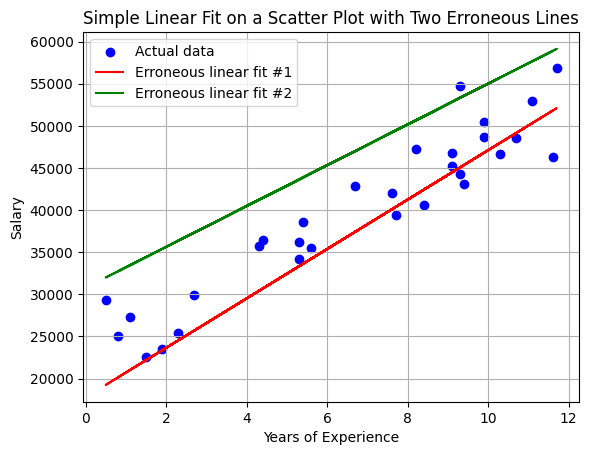

In [ ]:
# Generate two erroneous fitted lines to compare with the correct fitted line
ŷ_err_1 = m*(1.15) * x + b - 5000 
ŷ_err_2 = m*(0.95) * x + b + 8000

plt.scatter(x, y, c='blue', label='Actual data')
plt.plot(x, ŷ_err_1, c='red', label='Erroneous linear fit #1')
plt.plot(x, ŷ_err_2, c='green', label='Erroneous linear fit #2')
plt.xlabel('Years of Experience')  # X-axis label
plt.ylabel('Salary')  # Y-axis label
plt.title('Simple Linear Fit on a Scatter Plot with Two Erroneous Lines')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(f"The MAE in prediction #1 (wrong) is {round(mean_absolute_error(y,ŷ_err_1))} €")
print(f"The MAE in prediction #2 (wrong) is {round(mean_absolute_error(y,ŷ_err_2))} €")
print(f"The MAE in the correct prediction is {round(mean_absolute_error(y,ŷ))} €")

print(f"The MSE in prediction #1 (wrong) is {round(mean_squared_error(y,ŷ_err_1))} €²")
print(f"The MSE in prediction #2 (wrong) is {round(mean_squared_error(y,ŷ_err_2))} €²")
print(f"The MSE in the correct prediction is {round(mean_squared_error(y,ŷ))} €²")

print(f"The RMSE in prediction #1 (wrong) is {round(root_mean_squared_error(y, ŷ_err_1))} €")
print(f"The RMSE in prediction #2 (wrong) is {round(root_mean_squared_error(y, ŷ_err_2))} €")
print(f"The RMSE in the correct prediction is {round(root_mean_squared_error(y, ŷ))} €")

The MAE in prediction #1 (wrong) is 3320 €
The MAE in prediction #2 (wrong) is 7238 €
The MAE in the correct prediction is 2573 €
The MSE in prediction #1 (wrong) is 17659331 €²
The MSE in prediction #2 (wrong) is 61198563 €²
The MSE in the correct prediction is 9945705 €²
The RMSE in prediction #1 (wrong) is 4202 €
The RMSE in prediction #2 (wrong) is 7823 €
The RMSE in the correct prediction is 3154 €


We can observe that the error in both metrics is greater in the two erroneous lines than in the fitted line.

MAE and MSE are not the only ways to measure a regression model's error. The share of the variance it explains (R²), errors as a percentage of the true value, or the median of the absolute errors each answer a different question: [Measuring a regression model's error](../../evaluation/regression_metrics.ipynb) compares them.

## Model Fitting

We calculated our model with:
```python
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(x.reshape(-1, 1), y)
```

This function performed the fitting using the **ordinary least squares (OLS)** method. It is an optimization strategy that seeks to minimize the sum of the squares of the residuals (the difference between the actual values and those predicted by the model).

That is, it searched for the values of $m$ and $b$ that **minimize the mean squared error (MSE)**.

**Note on OLS:** least squares has an exact solution, for one feature or for many: a formula (the *normal equations*) computes the best parameters directly with matrix algebra, without iterating, which makes training very fast. Many other models have no such formula, logistic regression or Lasso among them, and are fitted step by step instead: [Gradient descent](../../ml-fundamentals/gradient_descent.ipynb).

## Prediction of New Values

Once we have the trained model, we can use it to predict the salary of an employee with a certain number of years of experience.

In [ ]:
x_new = np.array([1.5, 2.5, 4.5, 5.5, 6.5, 10]) # Create a vector with years of work experience for a series of potential new employees
ŷ_new = m * x_new + b # Calculate the estimated salary for each of them

Normally, it will be calculated directly using the `LinearRegression.predict()` method from scikit-learn. Remember that it was with the `LinearRegression` class that we created the model and that the values of m and b are in the `coef_` and `intercept_` attributes of the `model` object.

In [ ]:
ŷ_new = model.predict(x_new.reshape(-1, 1))

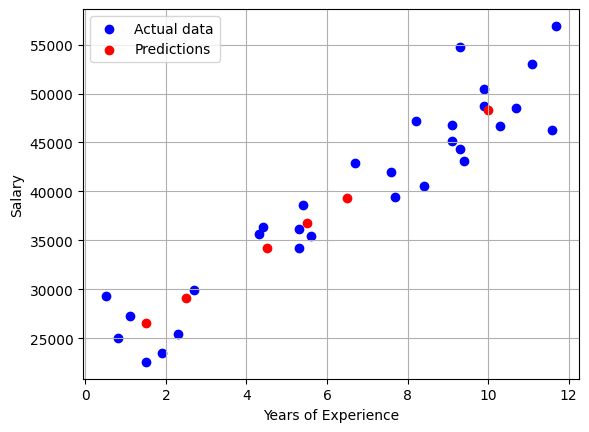

In [ ]:
plt.scatter(x, y, c='blue', label='Actual data')
plt.scatter(x_new, ŷ_new, c='red', label='Predictions')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

## Multiple Linear Regression

Just as with a single predictor, linear regression is represented as a line; with two predictors it would be represented as a plane; with three predictors as a hyperplane, etc.

Here you can see a visualization of a linear regression with 2 predictors in 3D: https://miabellaai.net/regression.html

## From Linear Regression to Other Machine Learning Models

Linear regression is one of the simplest machine learning models. In the case of simple linear regression, it is a model with 2 **parameters** (the slope and the y-intercept). It "learns" by finding the parameter values that best fit the data. This "fit" is achieved by minimizing a cost function; for standard linear regression, the sum of the squared residuals (the squared vertical distances from each data point to the line).

While the underlying logic and architecture of other models can be vastly different, many share this fundamental process: they use a learning algorithm to adjust their internal parameters to make a cost function as small as possible. The complexity of this process is what scales dramatically. For example, today's **large language models (LLMs)** have hundreds of billions of parameters to adjust, and the largest more than a trillion, compared to just the two in our simple line.

## Sources

- This notebook is based on [this one](https://github.com/FranPuentes/iTI2024/blob/main/Cap.%2017%20-%20regresi%C3%B3n%20lineal%20simple.ipynb) by [Juan Francisco Puentes Calvo](https://github.com/FranPuentes/iTI2024)
- [Linear Regression in Python](https://realpython.com/linear-regression-in-python)
- https://cienciadedatos.net/documentos/py10-regresion-lineal-python
- [Visualization of errors in linear regression](https://observablehq.com/@yizhe-ang/interactive-visualization-of-linear-regression)
- [Cost Function of Linear Regression: Deep Learning for Beginners](https://builtin.com/machine-learning/cost-function)